<a href="https://colab.research.google.com/github/amalasoy/Learnings-from-DSA-2/blob/main/case_study_unsupervised_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

1.Loading data set in python environment & making 'passenger id' as index column.

In [ ]:
df = pd.read_csv('/content/titanic_dataset.csv', index_col="PassengerId")

In [ ]:
df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


2.Fetching basic details.

In [ ]:
df.shape

(891, 11)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 891 entries, 1 to 891
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    object 
 3   Sex       891 non-null    object 
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    object 
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    object 
 10  Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 83.5+ KB


In [ ]:
df.isna().sum()

,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0
Cabin,687


In [ ]:
df.describe()

,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
type(df)

pandas.core.frame.DataFrame

3.Handling missing values

In [ ]:
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked']=df['Embarked'].fillna(df['Embarked'].mode()[0])


In [ ]:
df =df.drop('Cabin', axis = 1)

In [ ]:
df.isna().sum()

,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0
Embarked,0


In [ ]:
data = df.drop(['Name','Ticket'], axis = 1)

In [ ]:
data.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
PassengerId,,,,,,,,
1,0,3,male,22.0,1,0,7.2500,S
2,1,1,female,38.0,1,0,71.2833,C
3,1,3,female,26.0,0,0,7.9250,S
4,1,1,female,35.0,1,0,53.1000,S
5,0,3,male,35.0,0,0,8.0500,S


In [ ]:
data.columns

Index(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'Embarked'],
      dtype='object')

<Axes: >

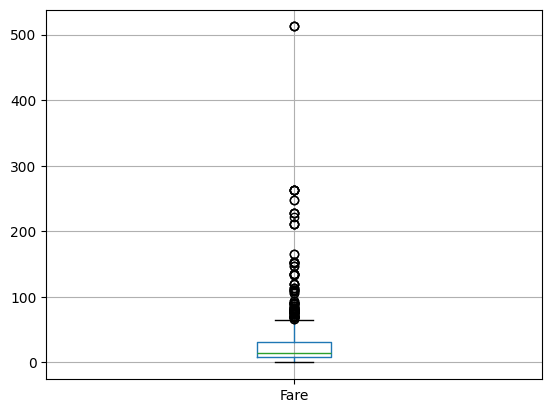

In [ ]:
data.boxplot('Fare')

<Axes: >

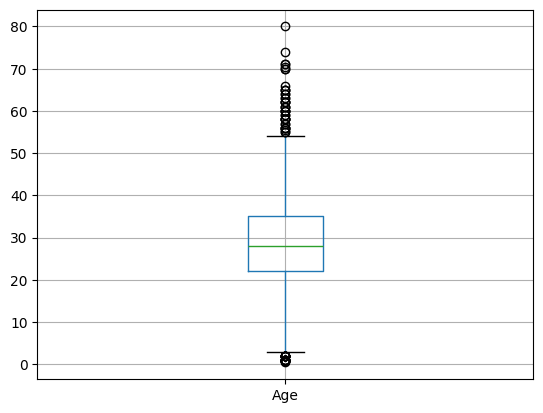

In [ ]:
data.boxplot('Age')

<Axes: >

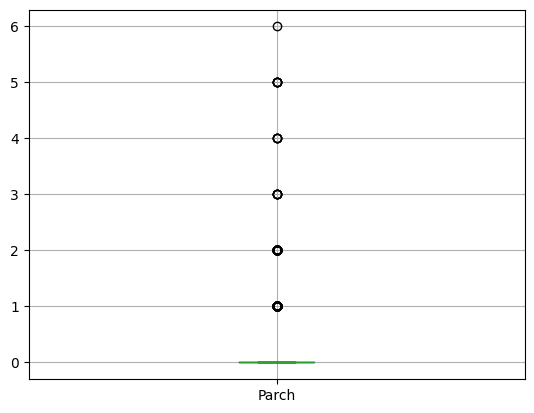

In [ ]:
data.boxplot('Parch')

In [ ]:
q1 = np.percentile(data['Fare'],25)
q2 = np.percentile(data['Fare'],50)
q3 = np.percentile(data['Fare'],75)
IQR = q3-q1
low_lim_fare = q1- IQR*1.5
upp_lim_fare = q3 + IQR*1.5
outlier=[]
for x in data['Fare']:
  if x<low_lim_fare or x > upp_lim_fare:
    outlier.append(x)

In [ ]:
data['Fare'] = data['Fare'].clip(lower=low_lim_fare, upper=upp_lim_fare)

In [ ]:
q1 = np.percentile(data['Age'],25)
q2 = np.percentile(data['Age'],50)
q3 = np.percentile(data['Age'],75)
IQR = q3-q1
low_lim_age = q1- IQR*1.5
upp_lim_age = q3 + IQR*1.5
outlier=[]
for x in data['Age']:
  if x<low_lim_age or x > upp_lim_age:
    outlier.append(x)

In [ ]:
data['Age'] = data['Age'].clip(lower=low_lim_age, upper=upp_lim_age)

In [ ]:
q1 = np.percentile(data['Parch'],25)
q2 = np.percentile(data['Parch'],50)
q3 = np.percentile(data['Parch'],75)
IQR = q3-q1
low_lim_Parch = q1- IQR*1.5
upp_lim_Parch = q3 + IQR*1.5
outlier=[]
for x in data['Parch']:
  if x<low_lim_Parch or x > upp_lim_Parch:
    outlier.append(x)

In [ ]:
data['Parch'] = data['Parch'].clip(lower=low_lim_Parch, upper=upp_lim_Parch)

<Axes: >

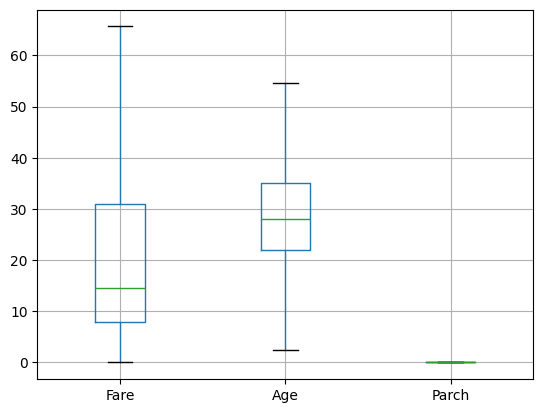

In [ ]:
data.boxplot(["Fare","Age","Parch"])

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 891 entries, 1 to 891
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       891 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  891 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 62.6+ KB


In [ ]:
data = pd.get_dummies(data,dtype = 'int')

In [ ]:
data.head()

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
PassengerId,,,,,,,,,,,
1,0,3,22.0,1,0,7.2500,0,1,0,0,1
2,1,1,38.0,1,0,65.6344,1,0,1,0,0
3,1,3,26.0,0,0,7.9250,1,0,0,0,1
4,1,1,35.0,1,0,53.1000,1,0,0,0,1
5,0,3,35.0,0,0,8.0500,0,1,0,0,1


4. Using different classification models for prediction

In [ ]:
x = data.drop("Survived", axis =1)

In [ ]:
y = data['Survived']

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y, test_size=0.2, random_state=42)

4a. Logistic regression

In [ ]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()

In [ ]:
model1 = lr.fit(x_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
y_pred_1 = lr.predict(x_test)

In [ ]:
y_pred_1

array([0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1,
       0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0,
       0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0,
       1, 1, 1])

In [ ]:
from sklearn.metrics import accuracy_score
accuracy_1 = model1.score(x_test,y_test)

In [ ]:
accuracy_1

0.7988826815642458

4b. K- means clustering

In [ ]:
df1 = df[['Sex','Survived']]

In [ ]:
df1.head()

,Sex,Survived
PassengerId,,
1,male,0
2,female,1
3,female,1
4,female,1
5,male,0


In [ ]:
from sklearn.preprocessing import LabelEncoder

In [ ]:
le = LabelEncoder()

In [ ]:
df1['Sex']= le.fit_transform(df1['Sex'])

/tmp/ipykernel_2081/4071306264.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1['Sex']= le.fit_transform(df1['Sex'])


In [ ]:
df1.head()

,Sex,Survived
PassengerId,,
1,1,0
2,0,1
3,0,1
4,0,1
5,1,0


In [ ]:
from sklearn.cluster import KMeans

In [ ]:
wcss=[]
for i in range(2,10):
  k_means = KMeans(n_clusters=i, init='k-means++', random_state=42)
  k_means.fit(df1)
  wcss.append(k_means.inertia_)

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_clusters (5). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_clusters (6). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_clusters (7). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_clusters (8). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:

Text(0, 0.5, 'wcss')

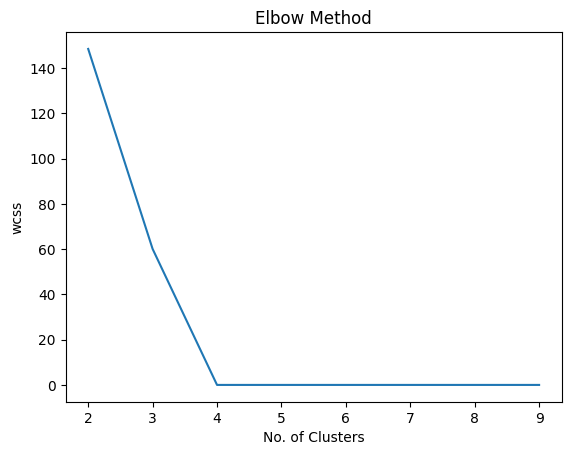

In [ ]:
plt.plot(range(2,10),wcss)
plt.title('Elbow Method')
plt.xlabel('No. of Clusters')
plt.ylabel('wcss')


In [ ]:
k_means = KMeans(n_clusters=4, init='k-means++', random_state=42)
y_kmeans = k_means.fit_predict(df1)

In [ ]:
y_kmeans

array([0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 3, 1, 0, 2, 3, 1, 0, 2,
       1, 2, 3, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 2, 0, 3, 1, 3, 3, 0, 1,
       1, 0, 0, 1, 0, 3, 0, 0, 1, 1, 0, 2, 1, 0, 1, 0, 0, 1, 0, 0, 0, 2,
       1, 0, 1, 0, 0, 3, 0, 0, 2, 0, 0, 0, 2, 1, 0, 2, 1, 0, 1, 1, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 2, 1, 0, 3, 0, 0, 0, 0, 0, 1, 2, 0, 1,
       0, 3, 0, 3, 3, 0, 0, 0, 0, 3, 0, 0, 0, 1, 0, 2, 0, 2, 1, 0, 0, 0,
       3, 1, 0, 0, 1, 0, 0, 0, 3, 1, 1, 0, 0, 0, 2, 3, 0, 0, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 2, 1, 3, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 3, 0, 0, 3, 0, 0, 2, 1, 0, 1, 2, 0, 0, 1, 0, 1, 2, 1, 1, 0, 0,
       1, 3, 0, 0, 0, 0, 2, 3, 0, 2, 1, 2, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0,
       2, 0, 0, 0, 2, 0, 2, 0, 0, 3, 1, 0, 0, 1, 0, 3, 0, 1, 0, 0, 3, 1,
       0, 0, 0, 0, 3, 1, 2, 0, 0, 3, 0, 0, 3, 1, 1, 1, 1, 1, 0, 2, 0, 0,
       3, 0, 0, 2, 1, 1, 0, 2, 1, 0, 1, 1, 3, 0, 0, 1, 0, 0, 0, 2, 0, 0,
       2, 0, 2, 1, 1, 1, 0, 3, 0, 0, 0, 3, 2, 1, 1,

In [ ]:
df1a =df1.iloc[:,[0,1]].values

In [ ]:
y_kmeans_1=k_means.fit_predict(df1a)

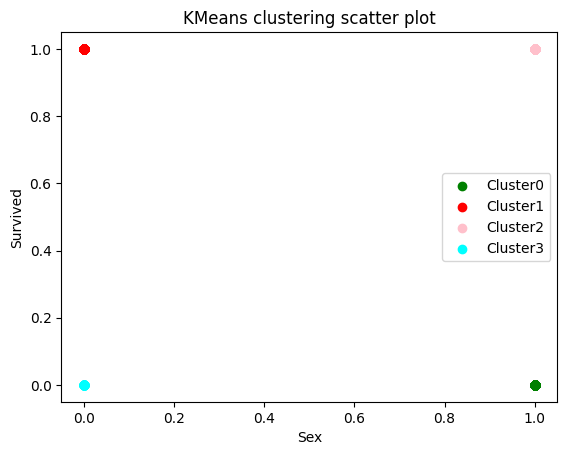

In [ ]:
colors=['g','r','pink','cyan']
for i in range(4):
  plt.scatter(df1a[y_kmeans==i,0],df1a[y_kmeans==i,1], c = colors[i], label=f'Cluster{i}')
plt.title('KMeans clustering scatter plot')
plt.xlabel('Sex')
plt.ylabel('Survived')
plt.legend( )

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
RFC = RandomForestClassifier()

In [ ]:
model_2 = RFC.fit(x_train,y_train)

In [ ]:
y_pred_2 = model_2.predict(x_test)

In [ ]:
y_pred_2

array([0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1,
       0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0,
       1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0,
       0, 1, 1])

In [ ]:
accuracy_2 = model_2.score(x_test,y_test)

In [ ]:
accuracy_2

0.8324022346368715

In [ ]:
from sklearn.tree import DecisionTreeClassifier
dtc = DecisionTreeClassifier(max_depth = 6, random_state=42)

In [ ]:
model_3 = dtc.fit(x_train,y_train)

In [ ]:
y_pred_3 = model_3.predict(x_test)

In [ ]:
y_pred_3

array([0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1,
       0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0,
       0, 1, 1])

In [ ]:
accuracy_3 = model_3.score(x_test,y_test)

In [ ]:
accuracy_3

0.8156424581005587

from above methods we got **Random Forest classifier** works best for this data set with better accuracy value

In [ ]:
print(accuracy_1,accuracy_2,accuracy_3)

0.7988826815642458 0.8324022346368715 0.8156424581005587
